# JAX-GCM (JCM) Demo 

<img src="../logo.png" alt="JAX-GCM Logo" width="200"/>

This notebook demonstrates the capabilities of JAX-GCM (JCM), a differentiable general circulation model built using JAX. 

We will showcase how to set up a simple atmospheric simulation, run the model, and visualize the results. Additionally, we will illustrate how to compute gradients with respect to model parameters using JAX's automatic differentiation features.



In [1]:
import sys, jax, jcm
print(sys.executable)
print(jcm.__file__)
print(jax.devices())

/home/chl256/jcm-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/chl256/jcm-env/bin/python
/home/chl256/jax-gcm/jcm/__init__.py
[CudaDevice(id=0)]


In [2]:
from jcm.model import Model
from jcm.terrain import TerrainData
from jcm.forcing import ForcingData
from importlib import resources
from jcm.physics.speedy.speedy_coords import get_speedy_coords

# Load the terrain and forcing data (interpolated to the default model grid)
data_dir = resources.files('jcm.data.bc.t30.clim')
coords = get_speedy_coords()
realistic_terrain = TerrainData.from_file(data_dir / 'terrain.nc', coords=coords)
realistic_forcing = ForcingData.from_file(data_dir / 'forcing.nc', coords=coords, align_mode='wrap_year')

In [3]:
model = Model(
    coords=coords,
    terrain=realistic_terrain,
)

In [4]:
predictions = model.run(
    save_interval=5,
    total_time=30,
    output_averages=True,
    forcing=realistic_forcing,
)

In [5]:
pred_ds = predictions.to_xarray()
pred_ds

<xarray.Dataset> Size: 29MB
Dimensions:                                                 (time: 6, level: 8,
                                                             lon: 96, lat: 48,
                                                             bounds: 2)
Coordinates:
  * time                                                    (time) datetime64[ms] 48B ...
  * level                                                   (level) float64 64B ...
    hybrid_a_full                                           (level) float64 64B ...
    hybrid_b_full                                           (level) float64 64B ...
  * lon                                                     (lon) float64 768B ...
  * lat                                                     (lat) float64 384B ...
Dimensions without coordinates: bounds
Data variables: (12/82)
    u_wind                                                  (time, level, lon, lat) float32 885kB ...
    v_wind                                                  (time, level, lon, lat) float32 885kB ...
    temperature                                             (time, level, lon, lat) float32 885kB ...
    specific_humidity                                       (time, level, lon, lat) float32 885kB ...
    geopotential                                            (time, level, lon, lat) float32 885kB ...
    normalized_surface_pressure                             (time, lon, lat) float32 111kB ...
    ...                                                      ...
    surface_exchange.wind_v                                 (time, lon, lat) float32 111kB ...
    surface_exchange.air_density                            (time, lon, lat) float32 111kB ...
    surface_exchange.air_potential_temperature              (time, lon, lat) float32 111kB ...
    water_positivity_correction.specific_humidity_tendency  (time, level, lon, lat) float32 885kB ...
    water_positivity_correction.total_water_tendency        (time, level, lon, lat) float32 885kB ...
    time_bounds                                             (time, bounds) datetime64[ms] 96B ...
Attributes:
    Conventions:                      CF-1.11
    omitted_interval_mean_variables:  convection.iptop,shortwave_rad.compute_...
    jcm_prov_params:                  {"speedy_clouds.params.ablcl1": 12.0, "...
    jcm_prov_params_sha:              0e520f33b0be

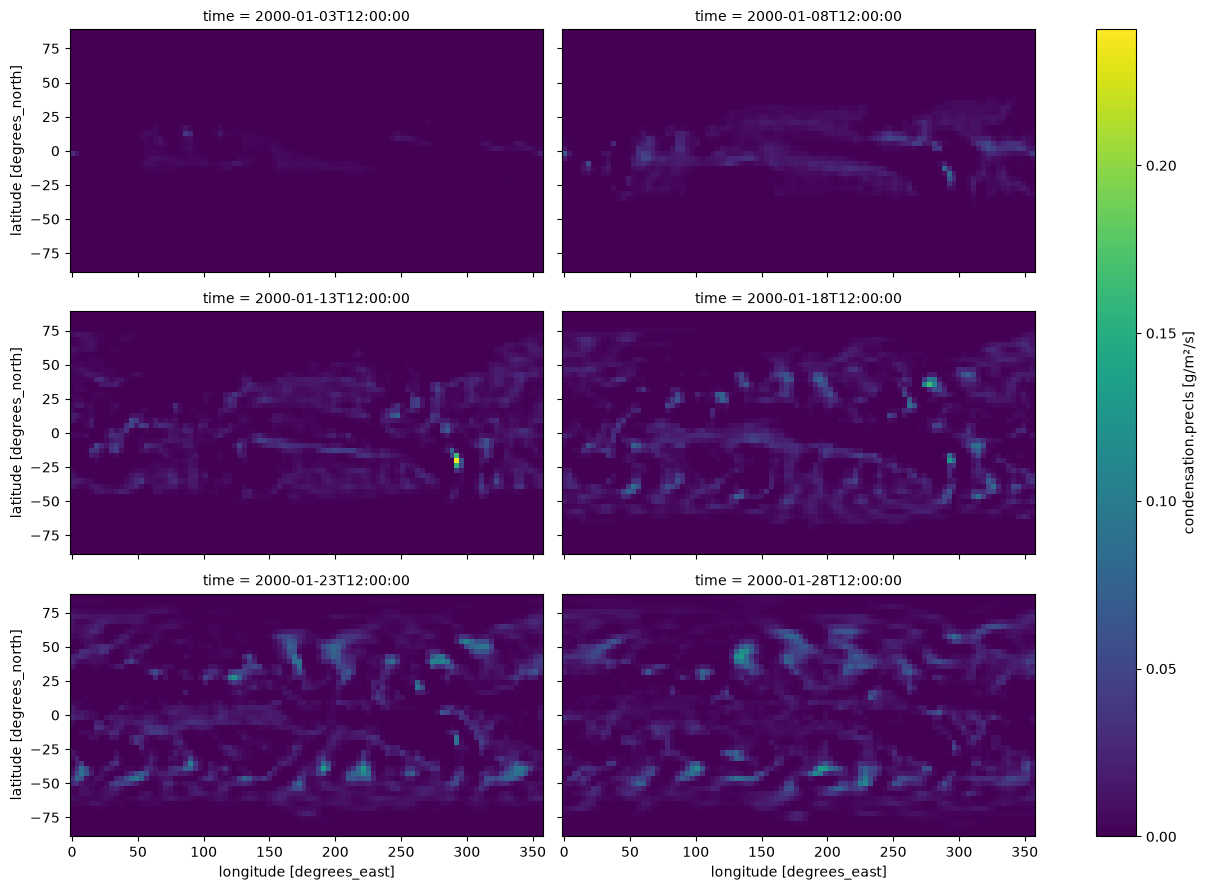

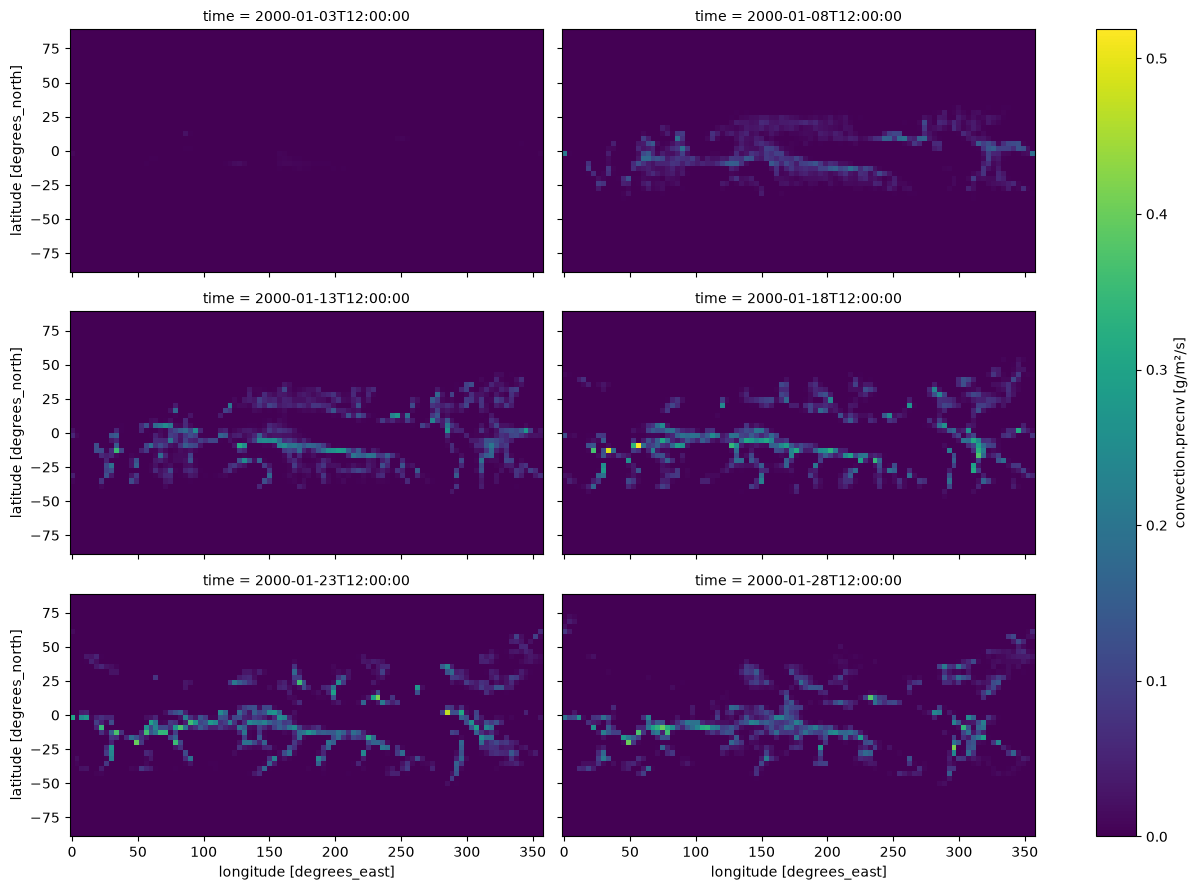

In [6]:
pred_ds['condensation.precls'].plot(x='lon', y='lat', col='time', col_wrap=2, aspect=2)
pred_ds['convection.precnv'].plot(x='lon', y='lat', col='time', col_wrap=2, aspect=2)

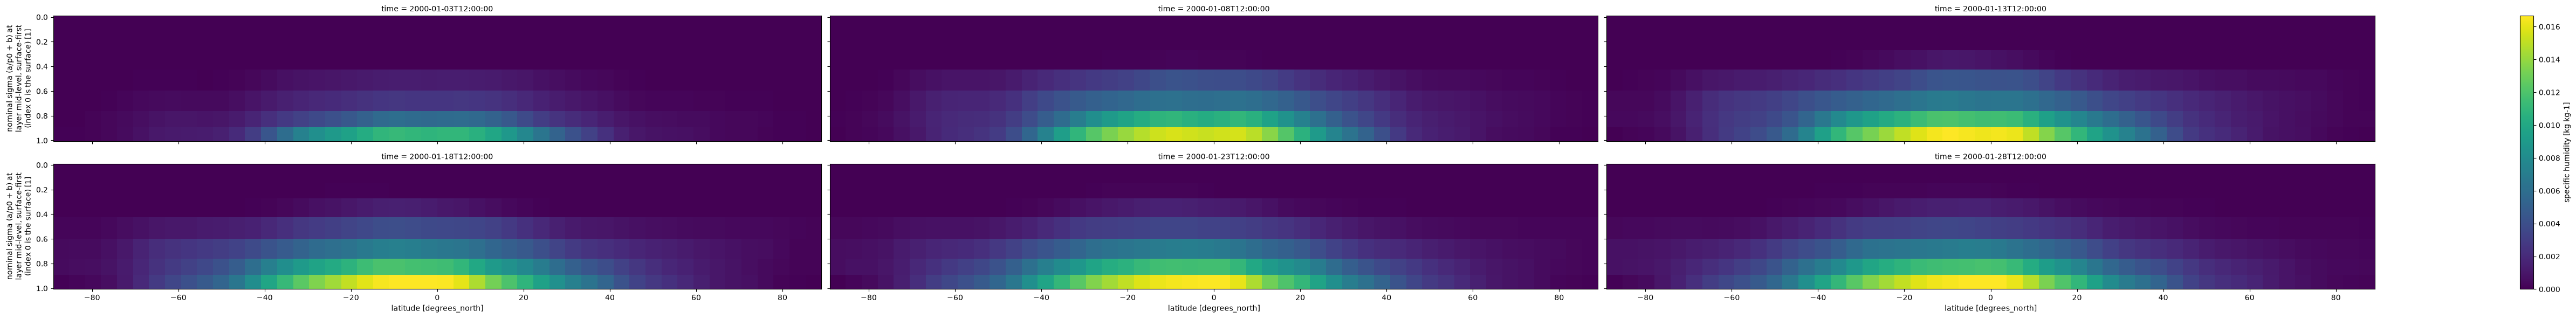

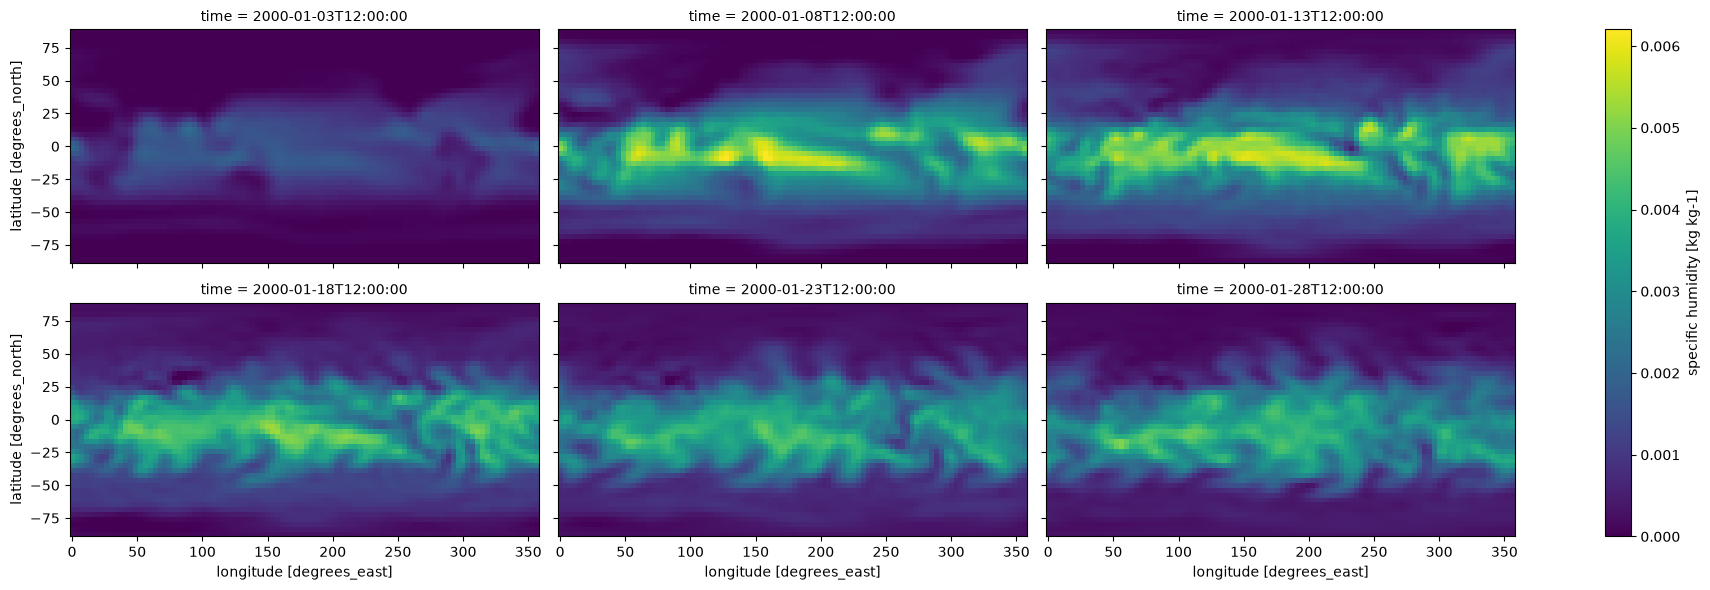

In [7]:
pred_ds['specific_humidity'].mean('lon').plot(x='lat', y='level', col='time', col_wrap=3, aspect=6, yincrease=False)
pred_ds['specific_humidity'].isel(level=3).plot(x='lon', y='lat', col='time', col_wrap=3, aspect=2)

### Clouds!

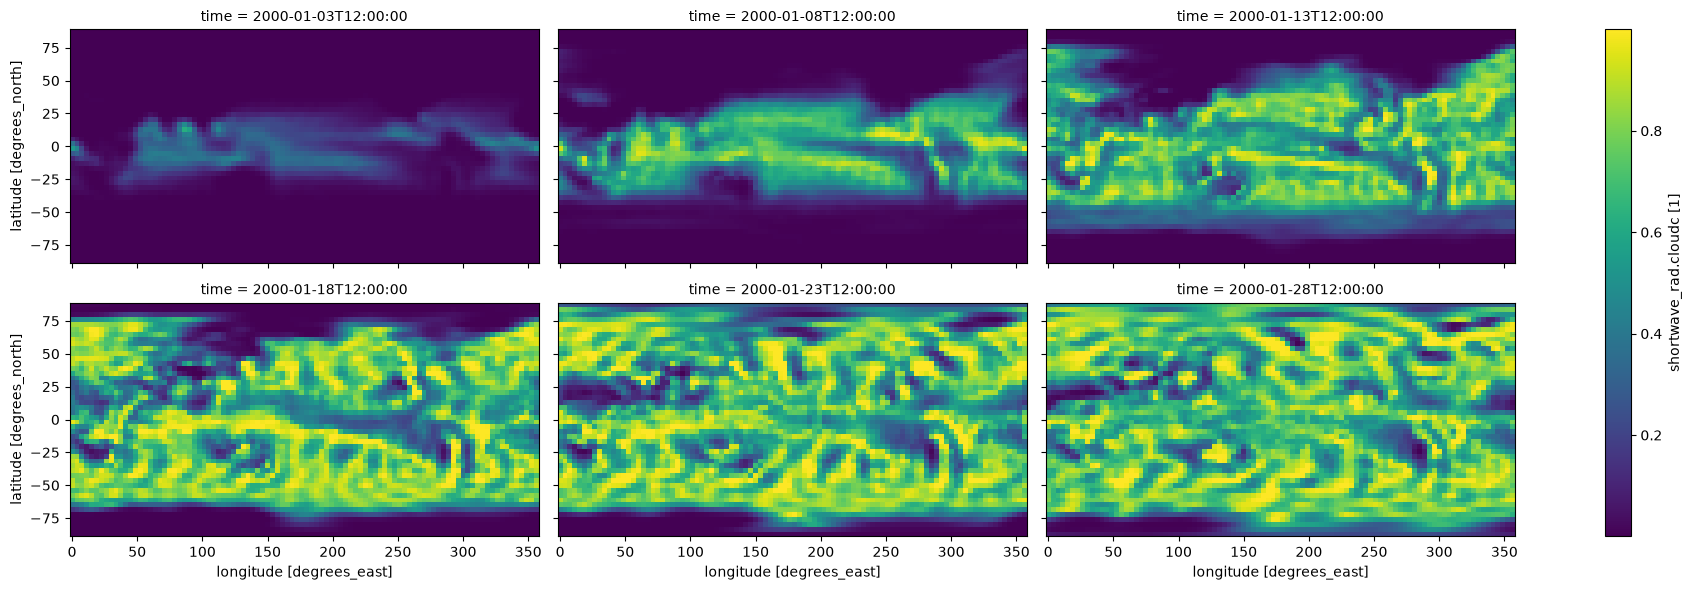

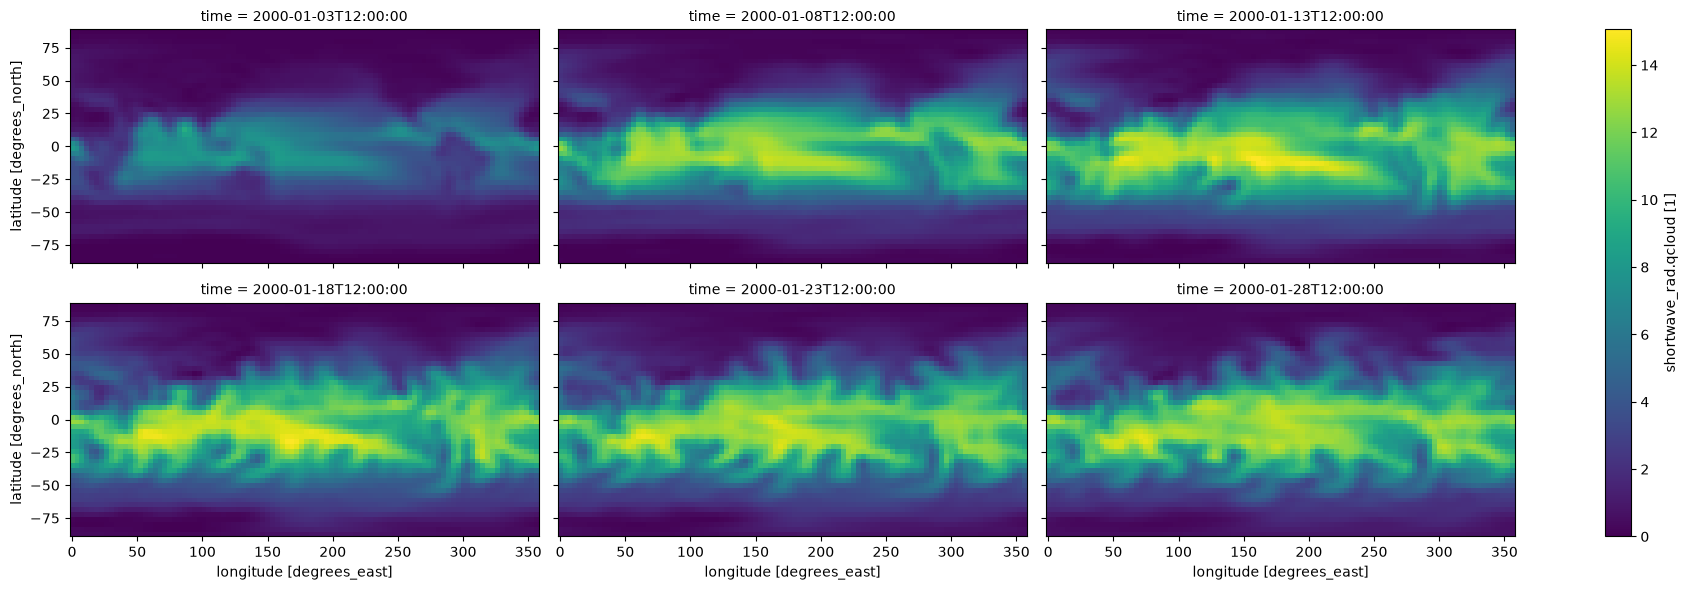

In [8]:
pred_ds['shortwave_rad.cloudc'].plot(x='lon', y='lat', col='time', col_wrap=3, aspect=2)
pred_ds['shortwave_rad.qcloud'].plot(x='lon', y='lat', col='time', col_wrap=3, aspect=2)

## Continue running

Continue a simulation from the previous state for an additional 30 days, saving every 5 days and outputting averages.


In [9]:
predictions = model.resume(
    total_time=30,
    output_averages=True,
    forcing=realistic_forcing,
)

Sometimes, for example in a coupled run we want a pure JAX interface to enable compilation of a larger model. We can do this using the `run_from_state` method:

```python
model.run_from_state(
    initial_state=model._final_dycore_state,
    total_time=30,
    output_averages=True,
    forcing=realistic_forcing,
)
```

## Note on speed and efficiency

Some preliminary tests show very good performance on a variety of devices but especially on GPUs and TPUs. For example, on a V100 GPU we see around 10x speedup compared to a CPU run. JCM also supports parallelization across multiple devices using JAX's `pmap` functionality, which can further enhance performance for large-scale simulations.

<center><img src="jcm_scaling.png" alt="JCM Performance" width="400"/></center>

## Model Gradients

We can compute gradients of model outputs with respect to model parameters using JAX's automatic differentiation. 

In [10]:
import jax
import jax.numpy as jnp
import jax.tree_util as jtu
from jcm.physics.speedy.speedy_terms import speedy_physics
from jcm.physics.speedy.params import Parameters

# Key step - create a function that makes a model given parameters
def model_run_wrapper(params):
    model = Model(coords=coords, terrain=realistic_terrain, physics=speedy_physics(parameters=params))

    return model.run(save_interval=1, total_time=1, forcing=realistic_forcing, output_averages=True)

In [11]:
# VJP is the vector-Jacobian product and calculates the gradient of outputs with respect to inputs

primal, vjp_fn = jax.vjp(model_run_wrapper, Parameters.default())

In [12]:
def create_cotangent(primal):
    cotangent = jtu.tree_map(jnp.zeros_like, primal)
    cotangent.physics['_shortwave_rad'].ftop = jtu.tree_map(jnp.ones_like, cotangent.physics['_shortwave_rad'].ftop)
    return cotangent

grad, = vjp_fn(create_cotangent(primal))

In [13]:
print(grad)

Parameters(convection=ConvectionParameters(psmin=0.0,
                                           trcnv=0.0,
                                           rhil=0.0,
                                           rhbl=0.0,
                                           entmax=0.0,
                                           smf=0.0,
                                           trigger_smoothing=0.0,
                                           precnv_smoothing=0.0,
                                           psmin_smoothing=0.0),
           condensation=CondensationParameters(trlsc=0.0,
                                               rhlsc=0.0,
                                               drhlsc=0.0,
                                               rhblsc=0.0,
                                               cap_smoothing=0.0,
                                               bl_threshold_smoothing=0.0),
           shortwave_radiation=ShortwaveRadiationParameters(albcl=-42.141014099121094,
                    

We can also calculate the Jacobian-vector product (JVP) to get gradients of specific outputs with respect to a parameter

In [14]:
# Define a tangent vector for JVP
params = Parameters.default()
tangent = Parameters.float_zeros()
tangent.mod_radcon.albsea = jnp.array(1.)

y, jvp_at_x = jax.jvp(model_run_wrapper, (params,), (tangent,))

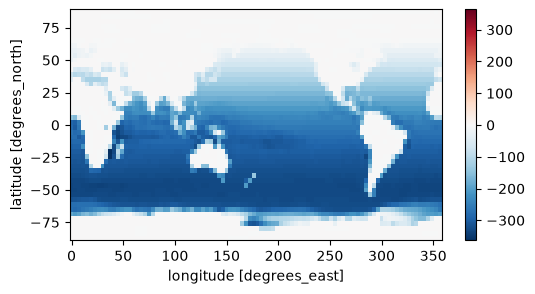

In [15]:
import xarray as xr
xr.DataArray(jvp_at_x.physics['_surface_flux'].hfluxn[0], dims=['lon', 'lat'],
                coords={'lat': pred_ds.lat, 'lon': pred_ds.lon}).plot(x='lon', y='lat', size=3, aspect=2)

## Advanced

Sometimes it can be useful to control the compilation or execution of the JAX code more directly. JAX has configuration functions to facilitate this.

In [16]:
print("JAX device:", jax.devices())

# import os
# os.environ["JAX_PLATFORM_NAME"] = "cpu"  # for use on ARM Macs

jax.config.update('jax_disable_jit', False) # disable if necessary for debugging
jax.config.update("jax_debug_infs", True) # watch for model blowup
jax.config.update("jax_debug_nans", False) # some physics fields might be nan

JAX device: [CudaDevice(id=0)]
